## Przegląd bibliotek ML i budowa pipeline'u treningowego
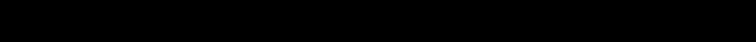
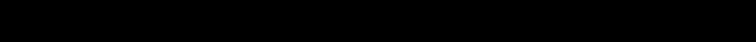
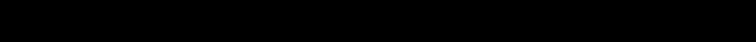

In [1]:
# import odpowiednich bibliotek
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.datasets import load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import time

In [2]:
# wczytanie zbiorów danych
data = load_wine(as_frame=True)
wine_data = data.data
wine_targets = data.target

### Testowanie biblioteki Scikit-learn na wybranym zbiorze

In [3]:
# podział danych na trening/test
TEST_SIZE = 0.2
RANDOM_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(wine_data, wine_targets, test_size=TEST_SIZE, random_state=RANDOM_SEED)

# stworzenie pipeline'u
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression())
])

In [4]:
# definiowanie tablic dla porownania
timestamps = []
accuracies = []
f1_scores = []

# trenowanie modelu
start_time = time.time()
pipeline.fit(X_train, y_train)
end_time = time.time() - start_time
timestamps.append(end_time)

# notowanie wyników
y_pred = pipeline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
accuracies.append(accuracy)
f1_score = f1_score(y_test, y_pred, average='micro')
f1_scores.append(f1_score)
classification_report = classification_report(y_test, y_pred)

# wyświetlenie rezultatu treningu
print("Accuracy: ", accuracy)
print("F1 Score: ", f1_score)
print(classification_report)

Accuracy:  1.0
F1 Score:  1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



### Tworzenie sieci neuronowej

In [5]:
# sprawdzenie wymiarów danych
print("Wymiary danych zapisanych: ", wine_data.shape)

Wymiary danych zapisanych:  (178, 13)


In [9]:
# wczytanie zbiorów danych
data = load_wine()
X = data.data
y = data.target

# standaryzacja cech i konwersja do tensorów
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# stworzenie tensorów
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Wymiary danych: ", X_train.shape)
print("Wymiar etykiet: ", y_train.shape)

Wymiary danych:  torch.Size([142, 13])
Wymiar etykiet:  torch.Size([142])


In [10]:
# definiowanie sieci neuronowej
deep_model = nn.Sequential(
    nn.Linear(13, 32),  # 13 cech wejściowych, 32 neurony
    nn.ReLU(),
    nn.Linear(32, 16),  # warstwa ukryta
    nn.ReLU(),
    nn.Linear(16, 3)    # 3 klasy wina
)

# zdefiniowanie optymalizatora i funkcji straty
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(deep_model.parameters(), lr=0.001)

In [11]:
# stworzenie pętli treningowej
EPOCHS = 30
new_start_time = time.time()
for epoch in range(EPOCHS):
    deep_model.train()

    # Forward pass
    outputs = deep_model(X_train)

    # Obliczenie straty
    loss = criterion(outputs, y_train)

    # Backpropagation i aktualizacja wag
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoka {epoch + 1}, loss: {loss.item():.4f}")
new_stop_time = time.time() - new_start_time
timestamps.append(new_stop_time)

Epoka 10, loss: 1.0464
Epoka 20, loss: 0.9822
Epoka 30, loss: 0.9158


In [12]:
# sprawdzenie jakości na zbiorze testowym
deep_model.eval()

with torch.no_grad():
    outputs = deep_model(X_test)
    predictions = torch.argmax(outputs, dim=1)

    accuracy = (predictions == y_test).float().mean().item()

print(f"Dokładność testowa: {accuracy * 100:.2f}%")


Dokładność testowa: 91.67%


## Sprawdzanie modelu uczenia maszynowego przy pomocy walidacji krzyżowej

In [13]:
# tworzenie konfiguracji walidacji krzyżowej
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# obliczenie wyników dla poszczególnych foldów
scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=kf,
    scoring="accuracy"
)

for i, score in enumerate(scores, start=1):
    print(f"Fold {i}: accuracy = {score:.4f}")

# średnia i odchylenie standardowe
mean_score = np.mean(scores)
std_score = np.std(scores)

print(f"\nŚrednia accuracy: {mean_score:.4f}")
print(f"Odchylenie standardowe: {std_score:.4f}")

cv_results = {
    "fold_scores": scores.tolist(),
    "mean_accuracy": float(mean_score),
    "std_accuracy": float(std_score)
}

Fold 1: accuracy = 1.0000
Fold 2: accuracy = 0.9722
Fold 3: accuracy = 1.0000
Fold 4: accuracy = 0.9714
Fold 5: accuracy = 1.0000

Średnia accuracy: 0.9887
Odchylenie standardowe: 0.0138

Zapisane wyniki: {'fold_scores': [1.0, 0.9722222222222222, 1.0, 0.9714285714285714, 1.0], 'mean_accuracy': 0.9887301587301588, 'std_accuracy': 0.013804961844545337}


## Tworzenie walidacji krzyżowej dla sieci neuronowej

In [14]:
# podział danych na 5 foldów
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

accuracies = []
timestamps = []
EPOCHS = 30

# Walidacja krzyżowa
for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
    print(f"\nFold {fold}/5")

    # podział danych na zbiór treningowy i testowy
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # konwersja danych do tensorów
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    # utworzenie nowej sieci dla danego foldu
    deep_model = nn.Sequential(
        nn.Linear(13, 32),
        nn.ReLU(),
        nn.Linear(32, 16),
        nn.ReLU(),
        nn.Linear(16, 3)
    )

    # funkcja straty i optymalizator
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(deep_model.parameters(), lr=0.001)

    # trening sieci
    start_time = time.time()

    for epoch in range(EPOCHS):
        deep_model.train()

        outputs = deep_model(X_train)
        loss = criterion(outputs, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    elapsed_time = time.time() - start_time
    timestamps.append(elapsed_time)

    # ocena modelu na zbiorze testowym
    deep_model.eval()

    with torch.no_grad():
        outputs = deep_model(X_test)
        predictions = torch.argmax(outputs, dim=1)

        accuracy = (predictions == y_test).float().mean().item()

    accuracies.append(accuracy)

    print(f"Loss: {loss.item():.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Czas treningu: {elapsed_time:.4f} s")

# podsumowanie wyników
mean_accuracy = np.mean(accuracies)
std_accuracy = np.std(accuracies)
total_time = sum(timestamps)

print("\nWyniki walidacji krzyżowej:")
for i, accuracy in enumerate(accuracies, start=1):
    print(f"Fold {i}: accuracy = {accuracy:.4f}")

print(f"\nŚrednia accuracy: {mean_accuracy:.4f}")
print(f"Odchylenie standardowe: {std_accuracy:.4f}")
print(f"Łączny czas treningu: {total_time:.4f} s")
print(f"Średni czas treningu na fold: {np.mean(timestamps):.4f} s")


Fold 1/5
Loss: 0.8625
Accuracy: 0.6667
Czas treningu: 0.0420 s

Fold 2/5
Loss: 0.8365
Accuracy: 0.5833
Czas treningu: 0.0340 s

Fold 3/5
Loss: 0.8837
Accuracy: 0.8056
Czas treningu: 0.0340 s

Fold 4/5
Loss: 0.9408
Accuracy: 0.6000
Czas treningu: 0.0492 s

Fold 5/5
Loss: 0.9508
Accuracy: 0.8000
Czas treningu: 0.0505 s

Wyniki walidacji krzyżowej:
Fold 1: accuracy = 0.6667
Fold 2: accuracy = 0.5833
Fold 3: accuracy = 0.8056
Fold 4: accuracy = 0.6000
Fold 5: accuracy = 0.8000

Średnia accuracy: 0.6911
Odchylenie standardowe: 0.0954
Łączny czas treningu: 0.2097 s
Średni czas treningu na fold: 0.0419 s
